# Method bench 3, Phase G: combinations, forest plots and the decision table

**Carry rule** (preregistered so the factorial cannot stall): the top 2 arms per family by the family's primary metric
go into a 3 × 3 × 3 factorial (baseline, top-1, top-2 per family), labelled **exploratory** when they did not help alone.
Carried (source: `evidence/pilot_scripts/method_bench_3/bench3_numbers.json`, key `carry`): gates ['B1p EM-Bayes pooled', 'B1 EM-Bayes hysteresis'], corrections ['L1 Poisson seam', 'P1 Pan C tile'],
decision arms ['Q1 1/t on C0 current two-date', 'PULb binned c']; exploratory: ['Q1 1/t on C0 current two-date', 'PULb binned c', 'L1 Poisson seam', 'P1 Pan C tile'].

**Interaction** = gain of the cell − the sum of its members' gains alone (all against production, on the cell's roads);
positive means the parts help each other. p-values are Holm-adjusted and quoted only where significant.

In [1]:
import sys, json
sys.path.insert(0, '../../evidence/pilot_scripts/method_bench_3')
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 70
import nbviz as V
num = V.numbers('G')
kept = V.kept_table('G')
tiles = json.loads((V.NB / 'G_tiles.json').read_text())
print('tiles:', tiles['chosen'])

tiles: [['thin cloud', '0_13_5'], ['thick cloud', '0_11_4'], ['clear', '0_15_8'], ['flooded', '2_20_58'], ['smoke tile', '2_23_44'], ['smoke tile', '2_19_55']]


## Forest plots
Flood calls: 21-seed accuracy gain vs production (points). Blue = interval above 0, red = below 0, grey = includes 0.

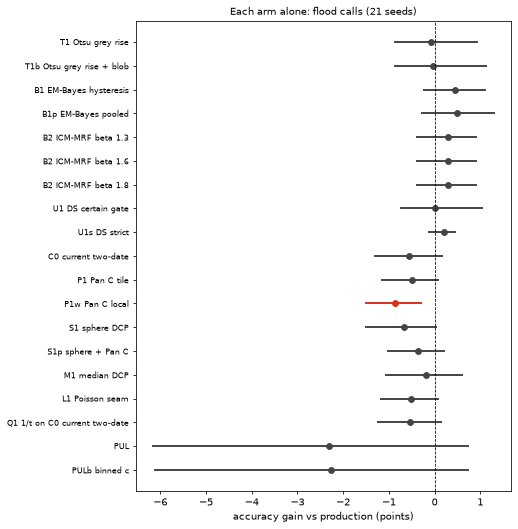

In [2]:
rows = [(n, 100 * r['seeds']['mean_gain'], 100 * r['seeds']['ci'][0], 100 * r['seeds']['ci'][1])
        for n, r in num['flood'].items()]
V.forest(rows, 'Each arm alone: flood calls (21 seeds)', 'accuracy gain vs production (points)')

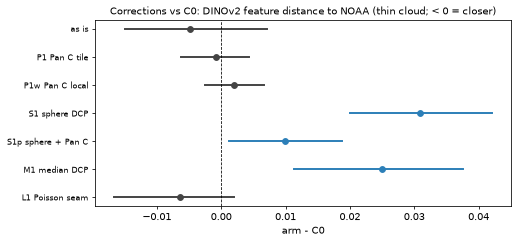

In [3]:
rows = [(n, r['mean_diff'], r['ci'][0], r['ci'][1]) for n, r in (num.get('ida_primary_vs_C0') or {}).items() if r]
V.forest(rows, 'Corrections vs C0: DINOv2 feature distance to NOAA (thin cloud; < 0 = closer)', 'arm - C0')

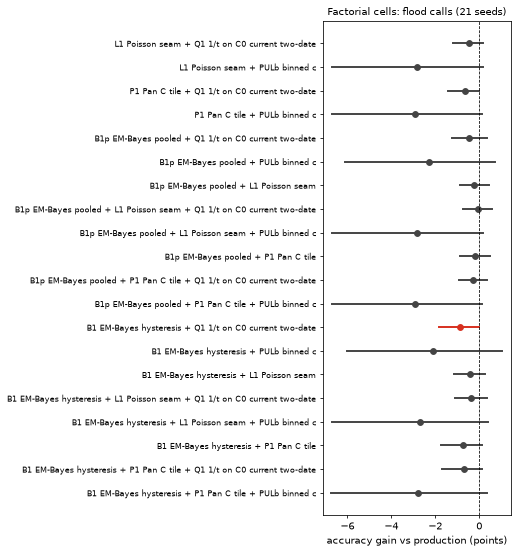

In [4]:
rows = [(n.replace('COMBO ', ''), 100 * r['mean_gain'], 100 * r['ci'][0], 100 * r['ci'][1]) for n, r in num.get('combo', {}).items()]
V.forest(rows, 'Factorial cells: flood calls (21 seeds)', 'accuracy gain vs production (points)')

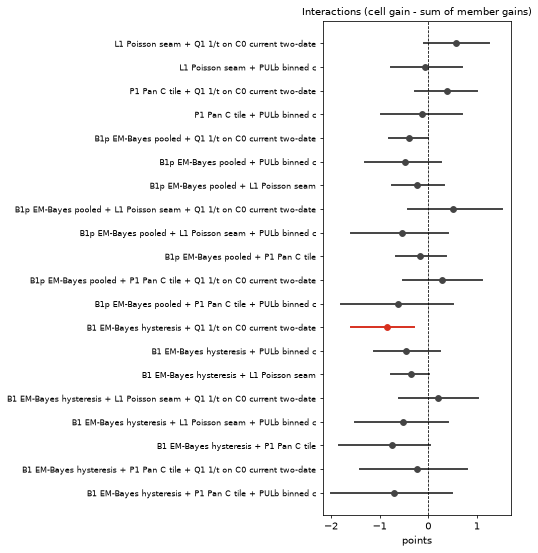

In [5]:
rows = [(n.replace('COMBO ', ''), 100 * r['interaction'], 100 * r['interaction_ci'][0], 100 * r['interaction_ci'][1]) for n, r in num.get('combo', {}).items()]
V.forest(rows, 'Interactions (cell gain - sum of member gains)', 'points')

## The top 3 cells on the same tiles
For each cell: its correction's output, its gate's mask and its flood calls at seed 662.

### `B1p EM-Bayes pooled + L1 Poisson seam + Q1 1/t on C0 current two-date`: gain -0.05 [-0.72, +0.59] points vs production; interaction +0.52 [-0.42, +1.53] (source: `bench3_numbers.json`, `combo`).

thin cloud: 0_13_5


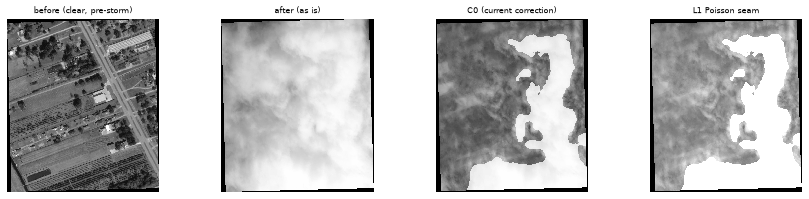

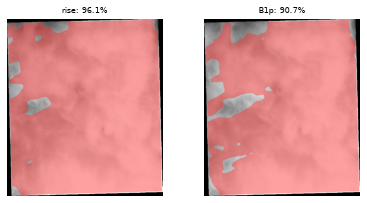

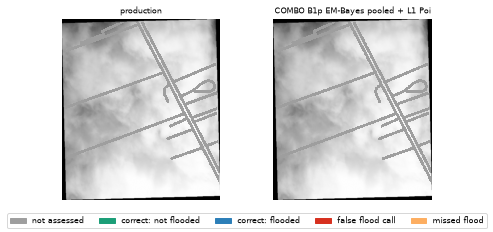

In [6]:
d = V.load('G', '0_13_5')
print('thin cloud: 0_13_5')
V.panel_images(d, ['L1 Poisson seam'])
V.panel_masks(d, ['rise'] + ['B1p'])
V.panel_calls(d, ['production', 'COMBO B1p EM-Bayes pooled + L1 Poisson seam + Q1 1/t on C0 current two-date'], kept)

thick cloud: 0_11_4


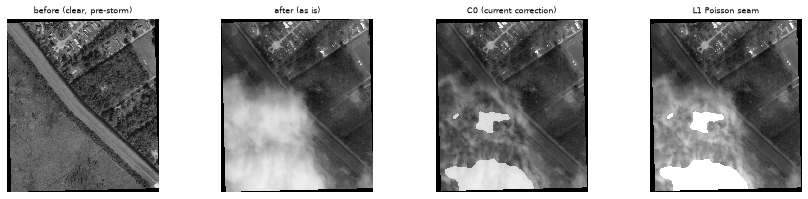

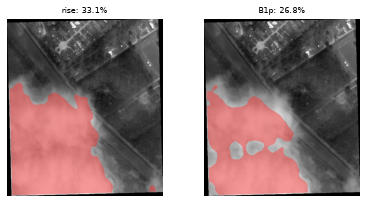

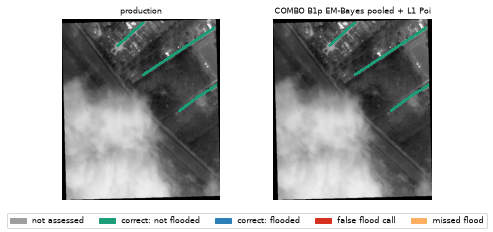

In [7]:
d = V.load('G', '0_11_4')
print('thick cloud: 0_11_4')
V.panel_images(d, ['L1 Poisson seam'])
V.panel_masks(d, ['rise'] + ['B1p'])
V.panel_calls(d, ['production', 'COMBO B1p EM-Bayes pooled + L1 Poisson seam + Q1 1/t on C0 current two-date'], kept)

clear: 0_15_8


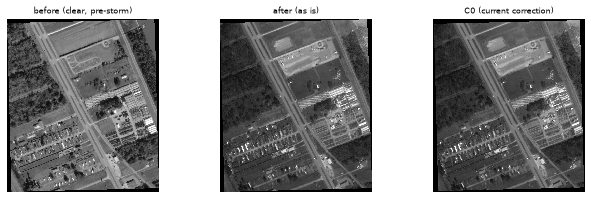

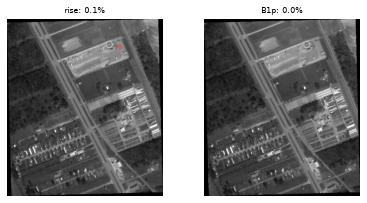

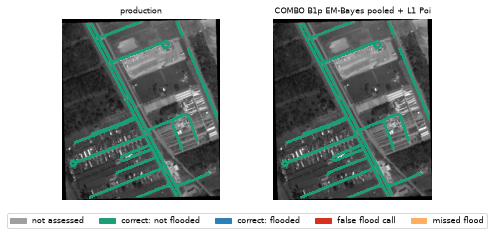

In [8]:
d = V.load('G', '0_15_8')
print('clear: 0_15_8')
V.panel_images(d, ['L1 Poisson seam'])
V.panel_masks(d, ['rise'] + ['B1p'])
V.panel_calls(d, ['production', 'COMBO B1p EM-Bayes pooled + L1 Poisson seam + Q1 1/t on C0 current two-date'], kept)

flooded: 2_20_58


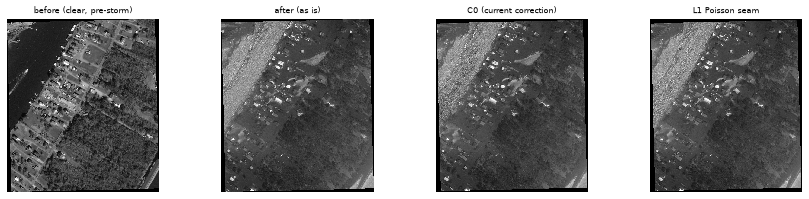

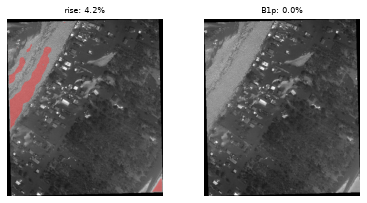

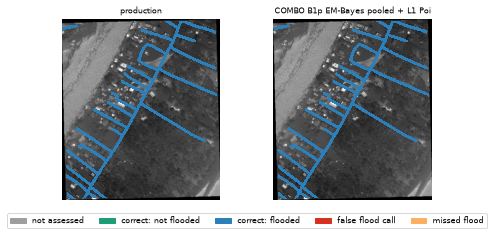

In [9]:
d = V.load('G', '2_20_58')
print('flooded: 2_20_58')
V.panel_images(d, ['L1 Poisson seam'])
V.panel_masks(d, ['rise'] + ['B1p'])
V.panel_calls(d, ['production', 'COMBO B1p EM-Bayes pooled + L1 Poisson seam + Q1 1/t on C0 current two-date'], kept)

### `B1p EM-Bayes pooled + P1 Pan C tile`: gain -0.18 [-0.85, +0.48] points vs production; interaction -0.16 [-0.66, +0.36] (source: `bench3_numbers.json`, `combo`).

thin cloud: 0_13_5


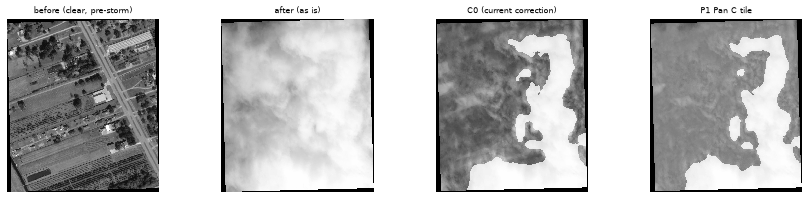

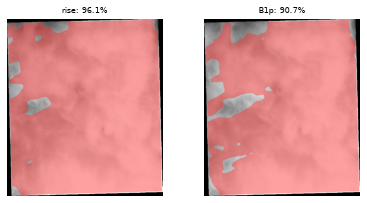

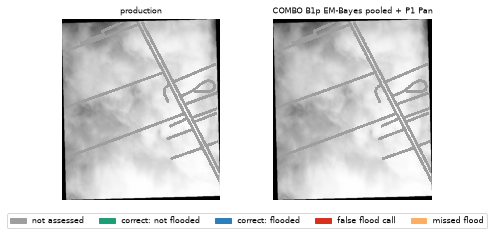

In [10]:
d = V.load('G', '0_13_5')
print('thin cloud: 0_13_5')
V.panel_images(d, ['P1 Pan C tile'])
V.panel_masks(d, ['rise'] + ['B1p'])
V.panel_calls(d, ['production', 'COMBO B1p EM-Bayes pooled + P1 Pan C tile'], kept)

thick cloud: 0_11_4


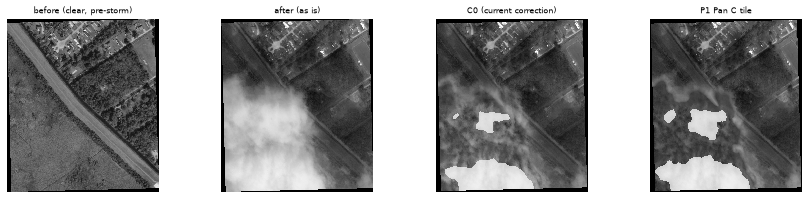

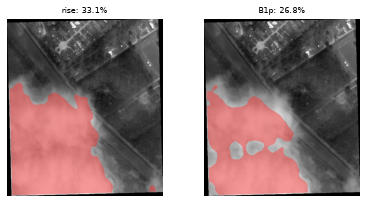

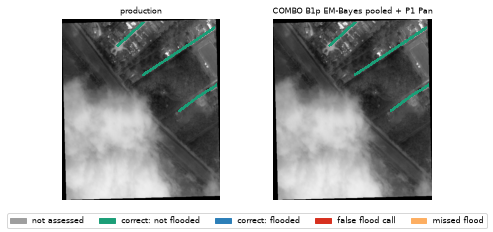

In [11]:
d = V.load('G', '0_11_4')
print('thick cloud: 0_11_4')
V.panel_images(d, ['P1 Pan C tile'])
V.panel_masks(d, ['rise'] + ['B1p'])
V.panel_calls(d, ['production', 'COMBO B1p EM-Bayes pooled + P1 Pan C tile'], kept)

clear: 0_15_8


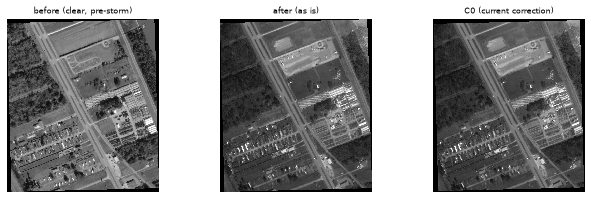

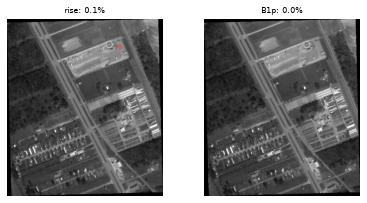

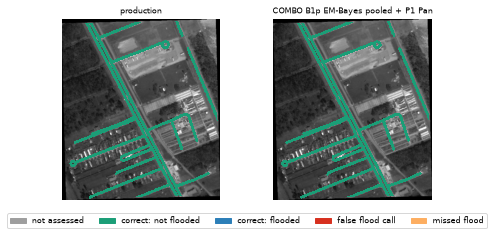

In [12]:
d = V.load('G', '0_15_8')
print('clear: 0_15_8')
V.panel_images(d, ['P1 Pan C tile'])
V.panel_masks(d, ['rise'] + ['B1p'])
V.panel_calls(d, ['production', 'COMBO B1p EM-Bayes pooled + P1 Pan C tile'], kept)

flooded: 2_20_58


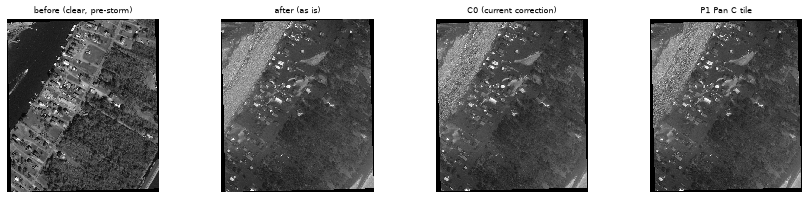

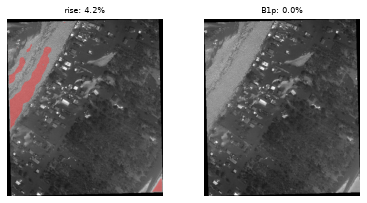

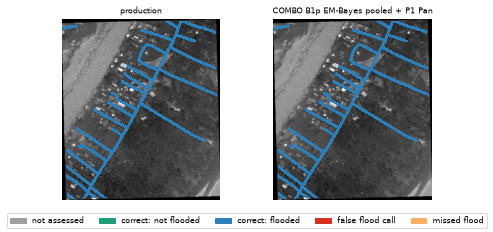

In [13]:
d = V.load('G', '2_20_58')
print('flooded: 2_20_58')
V.panel_images(d, ['P1 Pan C tile'])
V.panel_masks(d, ['rise'] + ['B1p'])
V.panel_calls(d, ['production', 'COMBO B1p EM-Bayes pooled + P1 Pan C tile'], kept)

### `B1p EM-Bayes pooled + L1 Poisson seam`: gain -0.25 [-0.89, +0.45] points vs production; interaction -0.22 [-0.75, +0.32] (source: `bench3_numbers.json`, `combo`).

thin cloud: 0_13_5


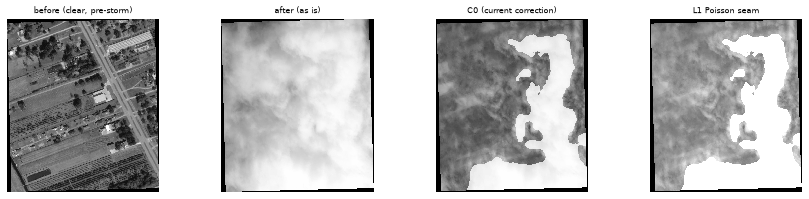

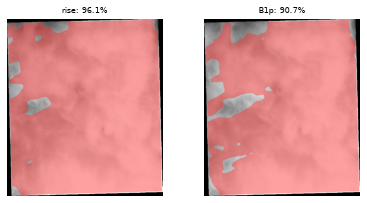

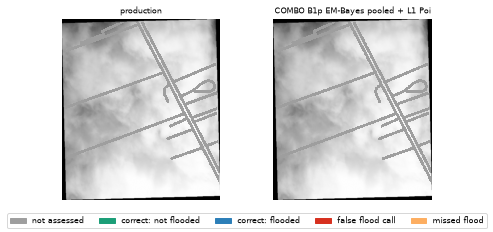

In [14]:
d = V.load('G', '0_13_5')
print('thin cloud: 0_13_5')
V.panel_images(d, ['L1 Poisson seam'])
V.panel_masks(d, ['rise'] + ['B1p'])
V.panel_calls(d, ['production', 'COMBO B1p EM-Bayes pooled + L1 Poisson seam'], kept)

thick cloud: 0_11_4


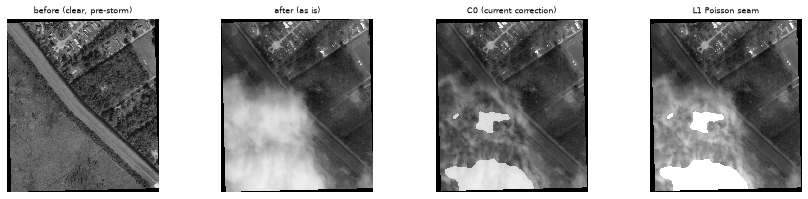

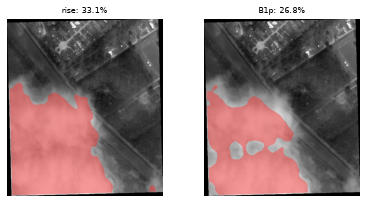

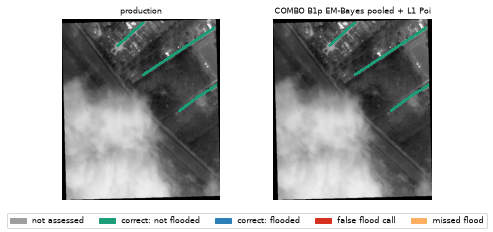

In [15]:
d = V.load('G', '0_11_4')
print('thick cloud: 0_11_4')
V.panel_images(d, ['L1 Poisson seam'])
V.panel_masks(d, ['rise'] + ['B1p'])
V.panel_calls(d, ['production', 'COMBO B1p EM-Bayes pooled + L1 Poisson seam'], kept)

clear: 0_15_8


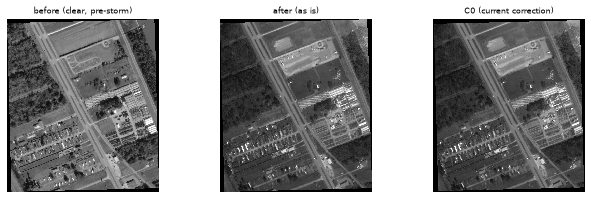

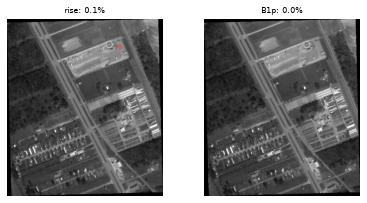

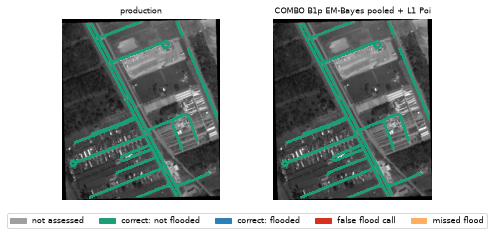

In [16]:
d = V.load('G', '0_15_8')
print('clear: 0_15_8')
V.panel_images(d, ['L1 Poisson seam'])
V.panel_masks(d, ['rise'] + ['B1p'])
V.panel_calls(d, ['production', 'COMBO B1p EM-Bayes pooled + L1 Poisson seam'], kept)

flooded: 2_20_58


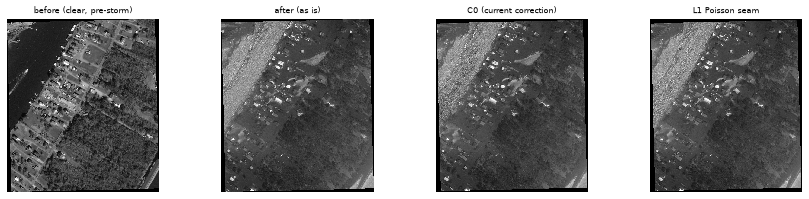

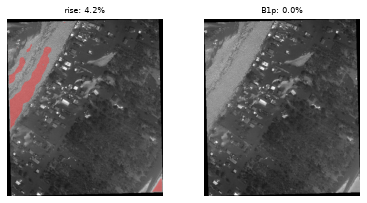

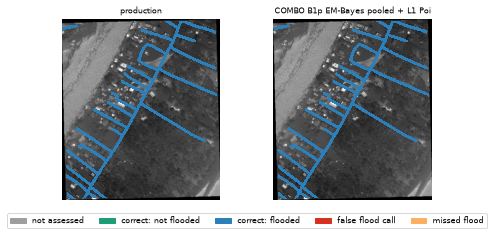

In [17]:
d = V.load('G', '2_20_58')
print('flooded: 2_20_58')
V.panel_images(d, ['L1 Poisson seam'])
V.panel_masks(d, ['rise'] + ['B1p'])
V.panel_calls(d, ['production', 'COMBO B1p EM-Bayes pooled + L1 Poisson seam'], kept)

## Decision table (for Justin; nothing is promoted)
Rules (preregistration): **KEEP** helps alone and in combination with an interval excluding 0; **MAYBE** helps on one metric only, or within noise; **DROP** no help or harms; **NOT RUN** not runnable or conditional. Source: `evidence/pilot_scripts/method_bench_3/bench3_decisions.json`.

In [18]:
pd.set_option('display.max_colwidth', 200)
pd.DataFrame(json.loads((V.HERE / 'bench3_decisions.json').read_text())['phase_G'])

,arm,decision,evidence
0,T1 Otsu grey rise,DROP,"no help: flood -0.08 [-0.87, +0.93] pts (9 seeds better, 11 worse); 91 roads added, 0 removed; accuracy on added roads 0.835 [0.710, 0.917]"
1,T1b Otsu grey rise + blob,DROP,"no help: flood -0.03 [-0.87, +1.13] pts (9 seeds better, 11 worse); 93 roads added, 0 removed; accuracy on added roads 0.839 [0.715, 0.920]"
2,B1 EM-Bayes hysteresis,MAYBE,"within noise / one metric: flood +0.45 [-0.24, +1.11] pts (14 seeds better, 6 worse); 34 roads added, 28 removed; accuracy on added roads 0.756 [0.546, 0.893]"
3,B1p EM-Bayes pooled,MAYBE,"within noise / one metric: flood +0.48 [-0.26, +1.30] pts (17 seeds better, 2 worse); 54 roads added, 0 removed; accuracy on added roads 0.757 [0.566, 0.884]"
4,B2 ICM-MRF beta 1.3,MAYBE,"within noise / one metric: flood +0.29 [-0.40, +0.90] pts (13 seeds better, 8 worse); 31 roads added, 39 removed; accuracy on added roads 0.762 [0.509, 0.911]"
5,B2 ICM-MRF beta 1.6,MAYBE,"within noise / one metric: flood +0.29 [-0.40, +0.90] pts (13 seeds better, 8 worse); 31 roads added, 39 removed; accuracy on added roads 0.762 [0.509, 0.911]"
6,B2 ICM-MRF beta 1.8,MAYBE,"within noise / one metric: flood +0.29 [-0.40, +0.90] pts (13 seeds better, 8 worse); 31 roads added, 39 removed; accuracy on added roads 0.762 [0.509, 0.911]"
7,U1 DS certain gate,MAYBE,"within noise / one metric: flood +0.02 [-0.74, +1.04] pts (9 seeds better, 11 worse); 78 roads added, 0 removed; accuracy on added roads 0.835 [0.702, 0.918]"
8,U1s DS strict,MAYBE,"within noise / one metric: flood +0.20 [-0.13, +0.45] pts (12 seeds better, 8 worse); 0 roads added, 3 removed"
9,P1 Pan C tile,DROP,"no help: Ida primary vs C0 -0.0007 [-0.0063, +0.0043] (73 tiles), guard 0.94 (ok); flood -0.50 [-1.15, +0.08] pts (6 seeds better, 15 worse); vs C0 current two-date +0.07 [-0.33, +0.43]"
